In [ ]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Random Forest Test Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00        16
           3       1.00      0.78      0.88        23
           4       0.71      1.00      0.83        12
           5       1.00      1.00      1.00         2

    accuracy                           0.92        65
   macro avg       0.95      0.96      0.95        65
weighted avg       0.95      0.92      0.93        65



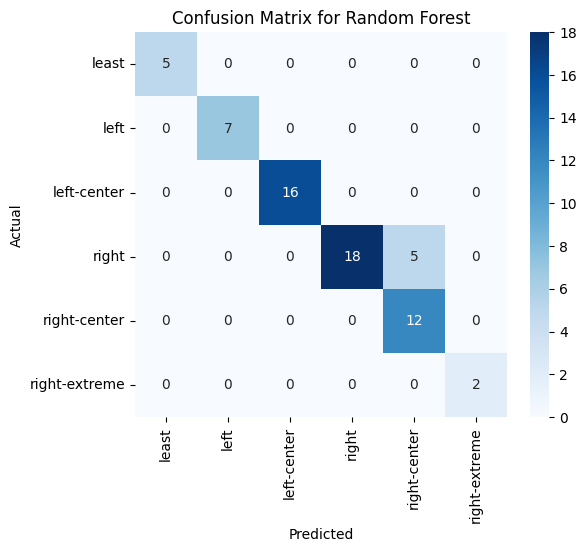

<ipython-input-12-6c3b21875cf4>:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')


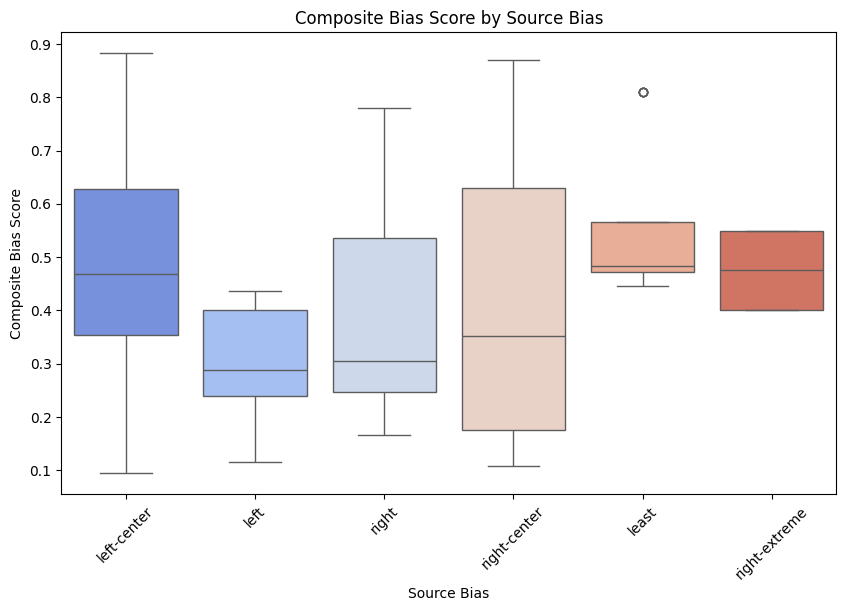


Summary of Composite Bias Scores:
count    215.000000
mean       0.431300
std        0.213200
min        0.094702
25%        0.289193
50%        0.399984
75%        0.567322
max        0.882629
Name: composite_bias, dtype: float64
Recall for class 'least': 1.00
Recall for class 'left': 1.00
Recall for class 'left-center': 1.00
Recall for class 'right': 0.78
Recall for class 'right-center': 1.00
Recall for class 'right-extreme': 1.00


In [ ]:
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.cluster import KMeans
from wordcloud import WordCloud
from textblob import TextBlob
import seaborn as sns
import matplotlib.pyplot as plt


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')


db = 'Sora_LREC2020_biasedsentences.csv'
data = pd.read_csv(db)


cleaned_db = data.dropna(subset=['reftext', 'docbody'])


cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')


def normalize_text(text):
    return text.translate(str.maketrans('', '', string.punctuation)).lower()

def stopwords_removal_after_tokenization(text):
    stop_words = set(stopwords.words('english'))
    return " ".join([word for word in word_tokenize(text) if word not in stop_words])

def text_lemmatized(text):
    lemmatizer = WordNetLemmatizer()
    return " ".join([lemmatizer.lemmatize(word) for word in word_tokenize(text)])


cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)

# Feature extraction using TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])


le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])


sia = SentimentIntensityAnalyzer()
cleaned_db['document_sentiment'] = cleaned_db['docbody'].apply(lambda x: sia.polarity_scores(x)['compound'])


def textblob_sentiment(text):
    return TextBlob(text).sentiment.polarity

def textblob_subjectivity(text):
    return TextBlob(text).sentiment.subjectivity

cleaned_db['textblob_sentiment'] = cleaned_db['docbody'].apply(textblob_sentiment)
cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(textblob_subjectivity)

# Latent Dirichlet Allocation (LDA)
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=42)
cleaned_db['cluster'] = kmeans.fit_predict(X)

# Composite Bias Calculation
def compute_composite_bias(row, sentiment_weight=0.3, subjectivity_weight=0.5, topic_weight=0.2, cluster_weight=0.1):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    topic_score = max(row['lda_topic_probabilities'])
    cluster_score = row['cluster']

    composite_bias_score = (sentiment_weight * sentiment_score +
                            subjectivity_weight * subjectivity_score +
                            topic_weight * topic_score +
                            cluster_weight * cluster_score)

    return composite_bias_score

cleaned_db['lda_topic_probabilities'] = [list(row) for row in lda_features]
cleaned_db['composite_bias'] = cleaned_db.apply(compute_composite_bias, axis=1)


X_train, X_test, y_train, y_test = train_test_split(X, cleaned_db['encoded_label'], test_size=0.3, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)


predicted_labels = model.predict(X_test)
accuracy_run_1 = accuracy_score(y_test, predicted_labels)

print(f"Random Forest Test Accuracy: {accuracy_run_1}")
print(classification_report(y_test, predicted_labels))


cm = confusion_matrix(y_test, predicted_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

from sklearn.metrics import classification_report

classification_report_1 = classification_report(y_test, predicted_labels, target_names=le.classes_, output_dict=True)


# Print recall for each class
for label, metrics in classification_report_1.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':  # Exclude averages
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")



[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Random Forest Test Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00        16
           3       1.00      0.78      0.88        23
           4       0.71      1.00      0.83        12
           5       1.00      1.00      1.00         2

    accuracy                           0.92        65
   macro avg       0.95      0.96      0.95        65
weighted avg       0.95      0.92      0.93        65



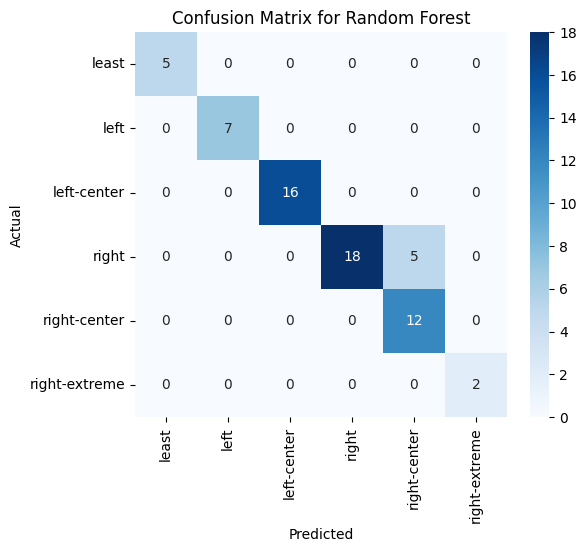

<ipython-input-13-f4fdee74d056>:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')


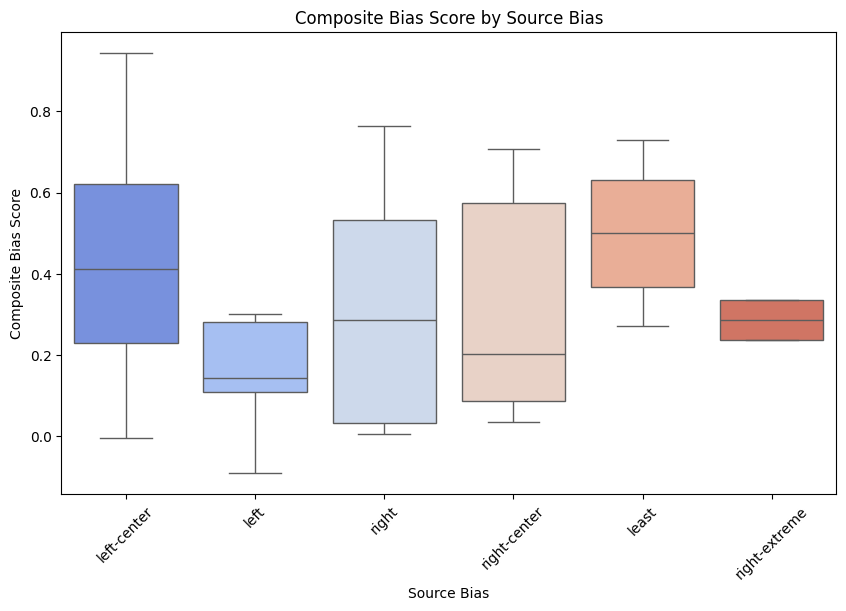


Summary of Composite Bias Scores:
count    215.000000
mean       0.344943
std        0.263301
min       -0.090471
25%        0.100719
50%        0.300705
75%        0.563638
max        0.943243
Name: composite_bias, dtype: float64
Recall for class 'least': 1.00
Recall for class 'left': 1.00
Recall for class 'left-center': 1.00
Recall for class 'right': 0.78
Recall for class 'right-center': 1.00
Recall for class 'right-extreme': 1.00


In [ ]:
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.cluster import KMeans
from wordcloud import WordCloud
from textblob import TextBlob
import seaborn as sns
import matplotlib.pyplot as plt


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')


db = 'Sora_LREC2020_biasedsentences.csv'
data = pd.read_csv(db)


cleaned_db = data.dropna(subset=['reftext', 'docbody'])


cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')


def normalize_text(text):
    return text.translate(str.maketrans('', '', string.punctuation)).lower()

def stopwords_removal_after_tokenization(text):
    stop_words = set(stopwords.words('english'))
    return " ".join([word for word in word_tokenize(text) if word not in stop_words])

def text_lemmatized(text):
    lemmatizer = WordNetLemmatizer()
    return " ".join([lemmatizer.lemmatize(word) for word in word_tokenize(text)])


cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)

# Feature extraction using TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])


le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])


sia = SentimentIntensityAnalyzer()
cleaned_db['document_sentiment'] = cleaned_db['docbody'].apply(lambda x: sia.polarity_scores(x)['compound'])


def textblob_sentiment(text):
    return TextBlob(text).sentiment.polarity

def textblob_subjectivity(text):
    return TextBlob(text).sentiment.subjectivity

cleaned_db['textblob_sentiment'] = cleaned_db['docbody'].apply(textblob_sentiment)
cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(textblob_subjectivity)

# Latent Dirichlet Allocation (LDA)
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=42)
cleaned_db['cluster'] = kmeans.fit_predict(X)

# Composite Bias Calculation
def compute_composite_bias(row, sentiment_weight=0.5, subjectivity_weight=0.1, topic_weight=0.3, cluster_weight=0.1):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    topic_score = max(row['lda_topic_probabilities'])
    cluster_score = row['cluster']

    composite_bias_score = (sentiment_weight * sentiment_score +
                            subjectivity_weight * subjectivity_score +
                            topic_weight * topic_score +
                            cluster_weight * cluster_score)

    return composite_bias_score

cleaned_db['lda_topic_probabilities'] = [list(row) for row in lda_features]
cleaned_db['composite_bias'] = cleaned_db.apply(compute_composite_bias, axis=1)


X_train, X_test, y_train, y_test = train_test_split(X, cleaned_db['encoded_label'], test_size=0.3, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)


predicted_labels = model.predict(X_test)
accuracy_run_2 = accuracy_score(y_test, predicted_labels)

print(f"Random Forest Test Accuracy: {accuracy_run_2}")
print(classification_report(y_test, predicted_labels))


cm = confusion_matrix(y_test, predicted_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

from sklearn.metrics import classification_report

classification_report_2 = classification_report(y_test, predicted_labels, target_names=le.classes_, output_dict=True)


# Print recall for each class
for label, metrics in classification_report_2.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':  # Exclude averages
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")




[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Random Forest Test Accuracy: 0.8615384615384616
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00        16
           3       1.00      0.61      0.76        23
           4       0.57      1.00      0.73        12
           5       1.00      1.00      1.00         2

    accuracy                           0.86        65
   macro avg       0.93      0.93      0.91        65
weighted avg       0.92      0.86      0.86        65



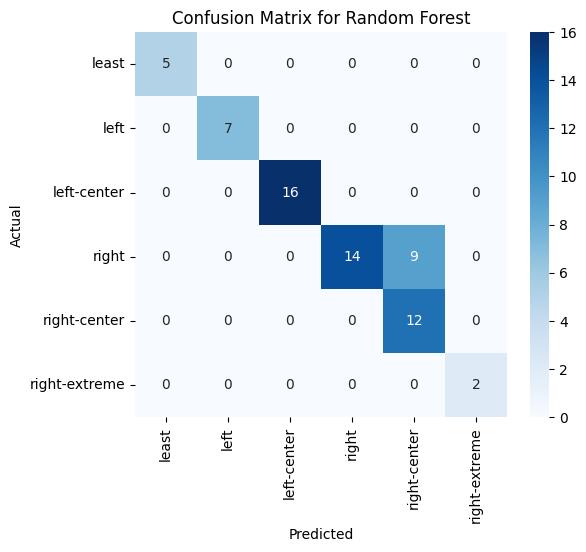

<ipython-input-14-7b87ebd5415e>:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')


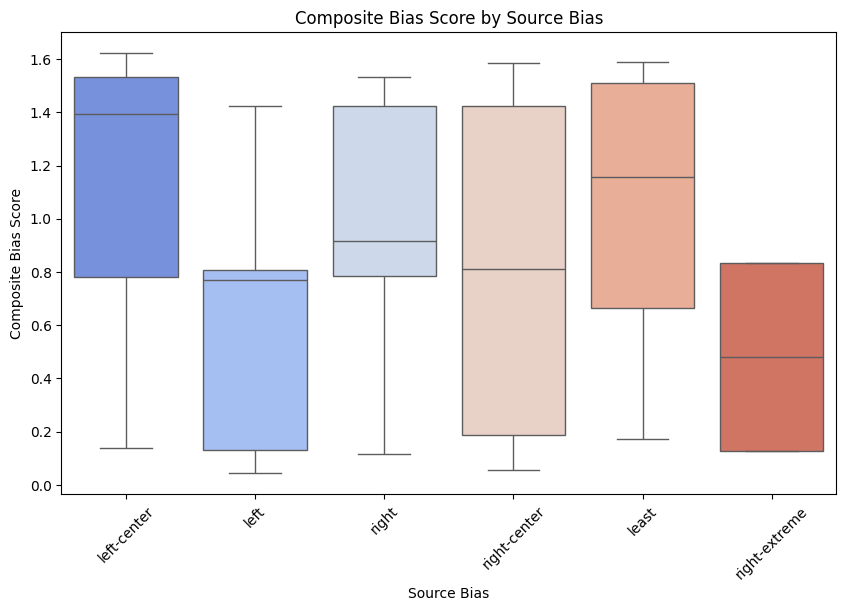


Summary of Composite Bias Scores:
count    215.000000
mean       0.907497
std        0.537908
min        0.043902
25%        0.734280
50%        0.828713
75%        1.436019
max        1.622014
Name: composite_bias, dtype: float64
Recall for class 'least': 1.00
Recall for class 'left': 1.00
Recall for class 'left-center': 1.00
Recall for class 'right': 0.61
Recall for class 'right-center': 1.00
Recall for class 'right-extreme': 1.00


In [ ]:

import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.cluster import KMeans
from wordcloud import WordCloud
from textblob import TextBlob
import seaborn as sns
import matplotlib.pyplot as plt


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')


db = 'Sora_LREC2020_biasedsentences.csv'
data = pd.read_csv(db)


cleaned_db = data.dropna(subset=['reftext', 'docbody'])


cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')


def normalize_text(text):
    return text.translate(str.maketrans('', '', string.punctuation)).lower()

def stopwords_removal_after_tokenization(text):
    stop_words = set(stopwords.words('english'))
    return " ".join([word for word in word_tokenize(text) if word not in stop_words])

def text_lemmatized(text):
    lemmatizer = WordNetLemmatizer()
    return " ".join([lemmatizer.lemmatize(word) for word in word_tokenize(text)])


cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)

# Feature extraction using TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])


le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])


sia = SentimentIntensityAnalyzer()
cleaned_db['document_sentiment'] = cleaned_db['docbody'].apply(lambda x: sia.polarity_scores(x)['compound'])


def textblob_sentiment(text):
    return TextBlob(text).sentiment.polarity

def textblob_subjectivity(text):
    return TextBlob(text).sentiment.subjectivity

cleaned_db['textblob_sentiment'] = cleaned_db['docbody'].apply(textblob_sentiment)
cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(textblob_subjectivity)

# Latent Dirichlet Allocation (LDA)
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=42)
cleaned_db['cluster'] = kmeans.fit_predict(X)

# Composite Bias Calculation
def compute_composite_bias(row, sentiment_weight=0.1, subjectivity_weight=0.1, topic_weight=0.1, cluster_weight=0.7):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    topic_score = max(row['lda_topic_probabilities'])
    cluster_score = row['cluster']

    composite_bias_score = (sentiment_weight * sentiment_score +
                            subjectivity_weight * subjectivity_score +
                            topic_weight * topic_score +
                            cluster_weight * cluster_score)

    return composite_bias_score

cleaned_db['lda_topic_probabilities'] = [list(row) for row in lda_features]
cleaned_db['composite_bias'] = cleaned_db.apply(compute_composite_bias, axis=1)


X_train, X_test, y_train, y_test = train_test_split(X, cleaned_db['encoded_label'], test_size=0.3, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)


predicted_labels = model.predict(X_test)
accuracy_run_3 = accuracy_score(y_test, predicted_labels)

print(f"Random Forest Test Accuracy: {accuracy_run_3}")
print(classification_report(y_test, predicted_labels))


cm = confusion_matrix(y_test, predicted_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

from sklearn.metrics import classification_report

classification_report_3 = classification_report(y_test, predicted_labels, target_names=le.classes_, output_dict=True)

for label, metrics in classification_report_3.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':  # Exclude averages
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")




[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Random Forest Test Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00        16
           3       1.00      0.78      0.88        23
           4       0.71      1.00      0.83        12
           5       1.00      1.00      1.00         2

    accuracy                           0.92        65
   macro avg       0.95      0.96      0.95        65
weighted avg       0.95      0.92      0.93        65



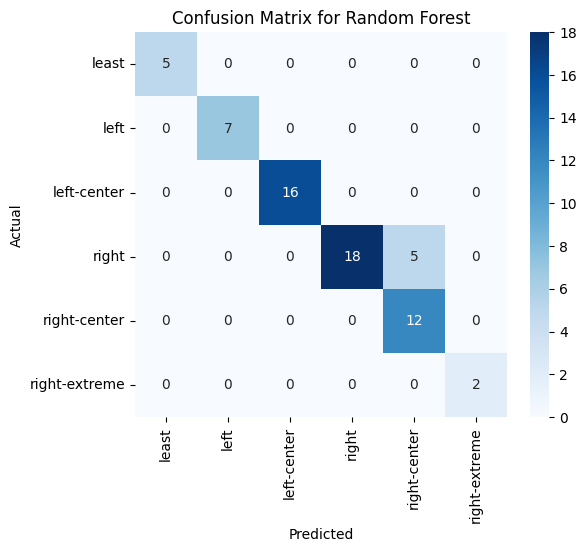

<ipython-input-15-6df51ae94dc7>:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')


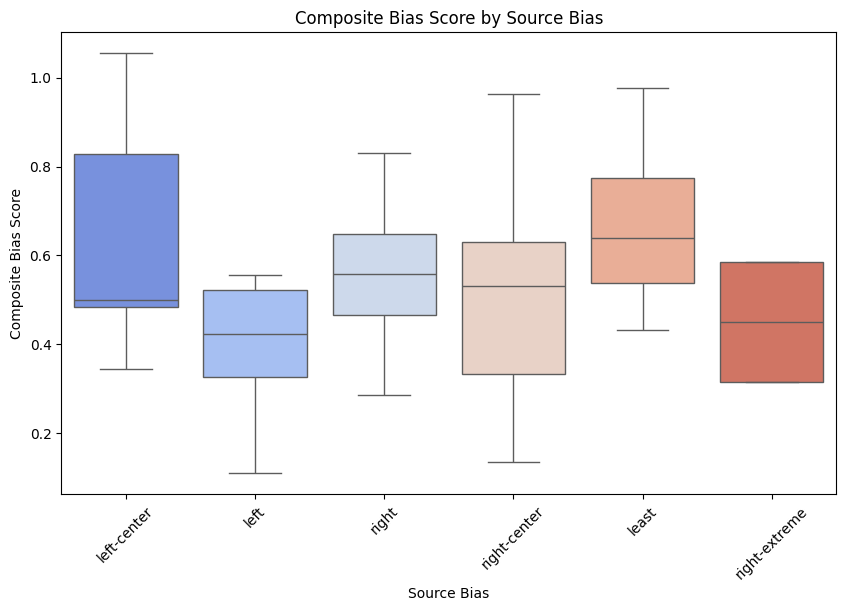


Summary of Composite Bias Scores:
count    215.000000
mean       0.559439
std        0.219771
min        0.109755
25%        0.423228
50%        0.522580
75%        0.686770
max        1.055036
Name: composite_bias, dtype: float64
Recall for class 'least': 1.00
Recall for class 'left': 1.00
Recall for class 'left-center': 1.00
Recall for class 'right': 0.78
Recall for class 'right-center': 1.00
Recall for class 'right-extreme': 1.00


In [ ]:

import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.cluster import KMeans
from wordcloud import WordCloud
from textblob import TextBlob
import seaborn as sns
import matplotlib.pyplot as plt


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')


db = 'Sora_LREC2020_biasedsentences.csv'
data = pd.read_csv(db)


cleaned_db = data.dropna(subset=['reftext', 'docbody'])


cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')


def normalize_text(text):
    return text.translate(str.maketrans('', '', string.punctuation)).lower()

def stopwords_removal_after_tokenization(text):
    stop_words = set(stopwords.words('english'))
    return " ".join([word for word in word_tokenize(text) if word not in stop_words])

def text_lemmatized(text):
    lemmatizer = WordNetLemmatizer()
    return " ".join([lemmatizer.lemmatize(word) for word in word_tokenize(text)])


cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)

# Feature extraction using TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])


le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])


sia = SentimentIntensityAnalyzer()
cleaned_db['document_sentiment'] = cleaned_db['docbody'].apply(lambda x: sia.polarity_scores(x)['compound'])


def textblob_sentiment(text):
    return TextBlob(text).sentiment.polarity

def textblob_subjectivity(text):
    return TextBlob(text).sentiment.subjectivity

cleaned_db['textblob_sentiment'] = cleaned_db['docbody'].apply(textblob_sentiment)
cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(textblob_subjectivity)

# Latent Dirichlet Allocation (LDA)
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=42)
cleaned_db['cluster'] = kmeans.fit_predict(X)

# Composite Bias Calculation
def compute_composite_bias(row, sentiment_weight=0.25, subjectivity_weight=0.25, topic_weight=0.25, cluster_weight=0.25):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    topic_score = max(row['lda_topic_probabilities'])
    cluster_score = row['cluster']

    composite_bias_score = (sentiment_weight * sentiment_score +
                            subjectivity_weight * subjectivity_score +
                            topic_weight * topic_score +
                            cluster_weight * cluster_score)

    return composite_bias_score

cleaned_db['lda_topic_probabilities'] = [list(row) for row in lda_features]
cleaned_db['composite_bias'] = cleaned_db.apply(compute_composite_bias, axis=1)


X_train, X_test, y_train, y_test = train_test_split(X, cleaned_db['encoded_label'], test_size=0.3, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)


predicted_labels = model.predict(X_test)
accuracy_run_4 = accuracy_score(y_test, predicted_labels)

print(f"Random Forest Test Accuracy: {accuracy_run_4}")
print(classification_report(y_test, predicted_labels))


cm = confusion_matrix(y_test, predicted_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

from sklearn.metrics import classification_report

classification_report_4 = classification_report(y_test, predicted_labels, target_names=le.classes_, output_dict=True)


# Print recall for each class
for label, metrics in classification_report_4.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")



<ipython-input-16-08dfb1b2d1ff>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='run', y='accuracy', data=accuracy_df, palette='Blues_d')


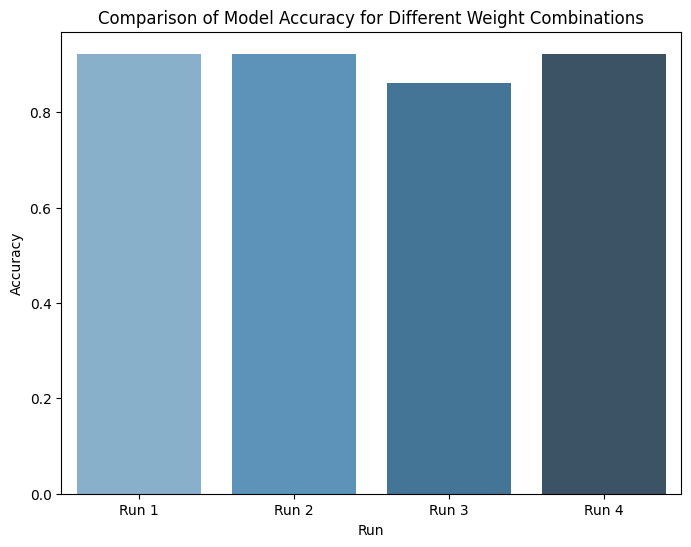

In [ ]:
# Store accuracy results for each run
accuracy_list = [
    {"run": "Run 1", "accuracy": accuracy_run_1},
    {"run": "Run 2", "accuracy": accuracy_run_2},
    {"run": "Run 3", "accuracy": accuracy_run_3},
    {"run": "Run 4", "accuracy": accuracy_run_4}    # Add more runs here
]

accuracy_df = pd.DataFrame(accuracy_list)

# Plot accuracy comparison
plt.figure(figsize=(8, 6))
sns.barplot(x='run', y='accuracy', data=accuracy_df, palette='Blues_d')
plt.title('Comparison of Model Accuracy for Different Weight Combinations')
plt.ylabel('Accuracy')
plt.xlabel('Run')
plt.show()




[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Random Forest Test Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00        16
           3       1.00      0.78      0.88        23
           4       0.71      1.00      0.83        12
           5       1.00      1.00      1.00         2

    accuracy                           0.92        65
   macro avg       0.95      0.96      0.95        65
weighted avg       0.95      0.92      0.93        65



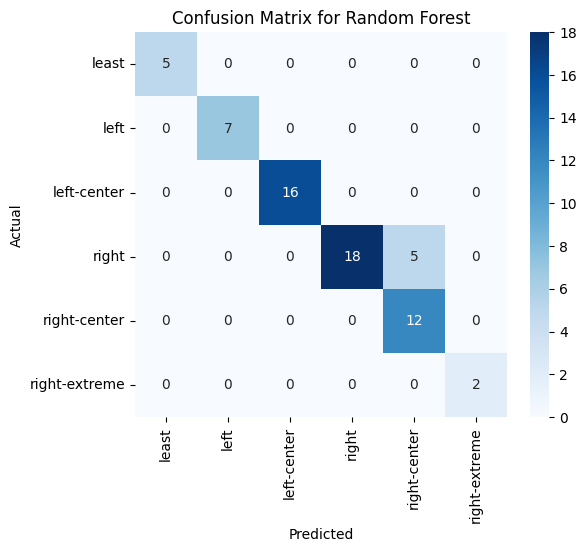

<ipython-input-17-c5950f3b9b6a>:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')


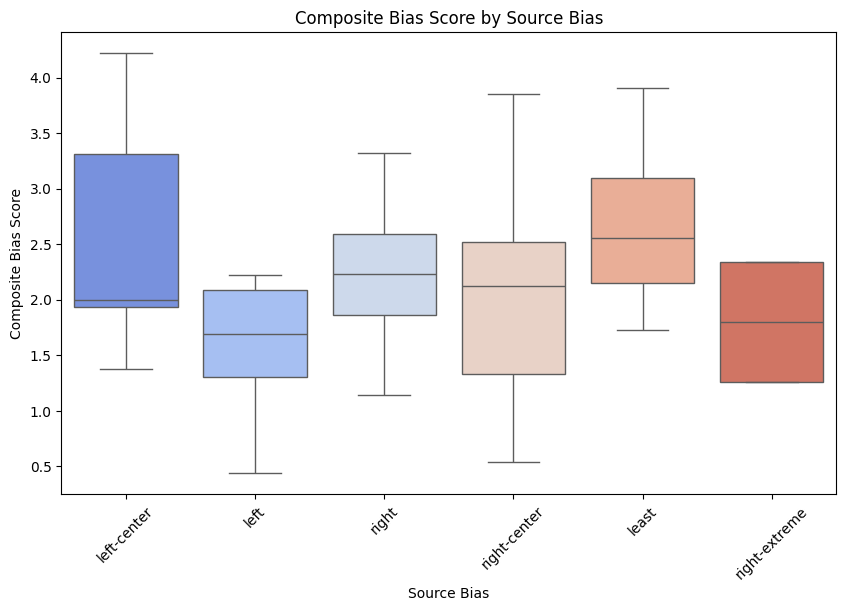


Summary of Composite Bias Scores:
count    215.000000
mean       2.237757
std        0.879085
min        0.439021
25%        1.692914
50%        2.090320
75%        2.747078
max        4.220143
Name: composite_bias, dtype: float64
Recall for class 'least': 1.00
Recall for class 'left': 1.00
Recall for class 'left-center': 1.00
Recall for class 'right': 0.78
Recall for class 'right-center': 1.00
Recall for class 'right-extreme': 1.00


In [ ]:

import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.cluster import KMeans
from wordcloud import WordCloud
from textblob import TextBlob
import seaborn as sns
import matplotlib.pyplot as plt


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')


db = 'Sora_LREC2020_biasedsentences.csv'
data = pd.read_csv(db)


cleaned_db = data.dropna(subset=['reftext', 'docbody'])


cleaned_db['source_bias'] = cleaned_db['source_bias'].replace('right-extream', 'right-extreme')

if 'article_bias' in cleaned_db.columns:
    cleaned_db['article_bias'] = cleaned_db['article_bias'].replace('right-extream', 'right-extreme')


def normalize_text(text):
    return text.translate(str.maketrans('', '', string.punctuation)).lower()

def stopwords_removal_after_tokenization(text):
    stop_words = set(stopwords.words('english'))
    return " ".join([word for word in word_tokenize(text) if word not in stop_words])

def text_lemmatized(text):
    lemmatizer = WordNetLemmatizer()
    return " ".join([lemmatizer.lemmatize(word) for word in word_tokenize(text)])


cleaned_db['reftext'] = cleaned_db['reftext'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)
cleaned_db['docbody'] = cleaned_db['docbody'].apply(normalize_text).apply(stopwords_removal_after_tokenization).apply(text_lemmatized)

# Feature extraction using TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(cleaned_db['docbody'])


le = LabelEncoder()
cleaned_db['encoded_label'] = le.fit_transform(cleaned_db['source_bias'])


sia = SentimentIntensityAnalyzer()
cleaned_db['document_sentiment'] = cleaned_db['docbody'].apply(lambda x: sia.polarity_scores(x)['compound'])


def textblob_sentiment(text):
    return TextBlob(text).sentiment.polarity

def textblob_subjectivity(text):
    return TextBlob(text).sentiment.subjectivity

cleaned_db['textblob_sentiment'] = cleaned_db['docbody'].apply(textblob_sentiment)
cleaned_db['textblob_subjectivity'] = cleaned_db['docbody'].apply(textblob_subjectivity)

# Latent Dirichlet Allocation (LDA)
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda_features = lda.fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=42)
cleaned_db['cluster'] = kmeans.fit_predict(X)

# Composite Bias Calculation
def compute_composite_bias(row):
    sentiment_score = row['document_sentiment']
    subjectivity_score = row['textblob_subjectivity']
    topic_score = max(row['lda_topic_probabilities'])
    cluster_score = row['cluster']

    composite_bias_score = (sentiment_score +
                           subjectivity_score +
                            topic_score +
                            cluster_score)

    return composite_bias_score

cleaned_db['lda_topic_probabilities'] = [list(row) for row in lda_features]
cleaned_db['composite_bias'] = cleaned_db.apply(compute_composite_bias, axis=1)


X_train, X_test, y_train, y_test = train_test_split(X, cleaned_db['encoded_label'], test_size=0.3, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)


predicted_labels = model.predict(X_test)
accuracy_run_5 = accuracy_score(y_test, predicted_labels)

print(f"Random Forest Test Accuracy: {accuracy_run_5}")
print(classification_report(y_test, predicted_labels))


cm = confusion_matrix(y_test, predicted_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix for Random Forest")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


plt.figure(figsize=(10, 6))
sns.boxplot(x='source_bias', y='composite_bias', data=cleaned_db, palette='coolwarm')
plt.title('Composite Bias Score by Source Bias')
plt.xlabel('Source Bias')
plt.ylabel('Composite Bias Score')
plt.xticks(rotation=45)
plt.show()

# Summary of Composite Bias Scores
print("\nSummary of Composite Bias Scores:")
print(cleaned_db['composite_bias'].describe())

from sklearn.metrics import classification_report

classification_report_5 = classification_report(y_test, predicted_labels, target_names=le.classes_, output_dict=True)


# Print recall for each class
for label, metrics in classification_report_5.items():
    if label != 'accuracy' and label != 'macro avg' and label != 'weighted avg':  # Exclude averages
        print(f"Recall for class '{label}': {metrics['recall']:.2f}")



<ipython-input-18-afcb97d9736d>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='run', y='accuracy', data=accuracy_df, palette='Blues_d')


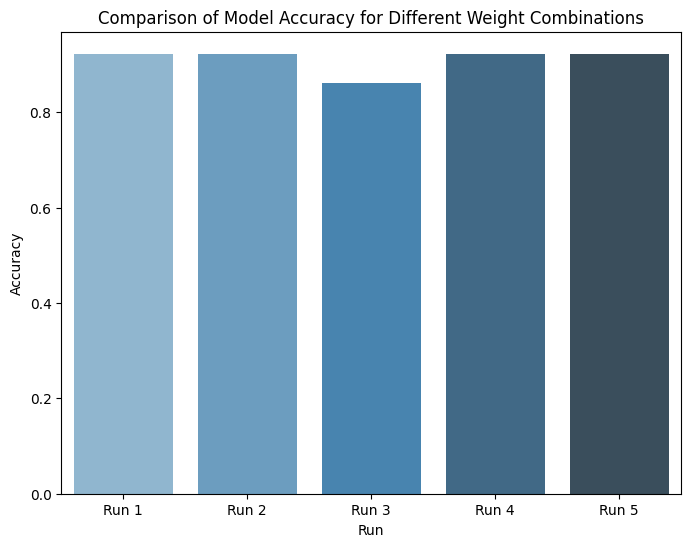

In [ ]:
# Store accuracy results for each run
accuracy_list = [
    {"run": "Run 1", "accuracy": accuracy_run_1},
    {"run": "Run 2", "accuracy": accuracy_run_2},
    {"run": "Run 3", "accuracy": accuracy_run_3},
    {"run": "Run 4", "accuracy": accuracy_run_4},
    {"run": "Run 5","accuracy": accuracy_run_5} # Add more runs here
]

accuracy_df = pd.DataFrame(accuracy_list)

# Plot accuracy comparison
plt.figure(figsize=(8, 6))
sns.barplot(x='run', y='accuracy', data=accuracy_df, palette='Blues_d')
plt.title('Comparison of Model Accuracy for Different Weight Combinations')
plt.ylabel('Accuracy')
plt.xlabel('Run')
plt.show()

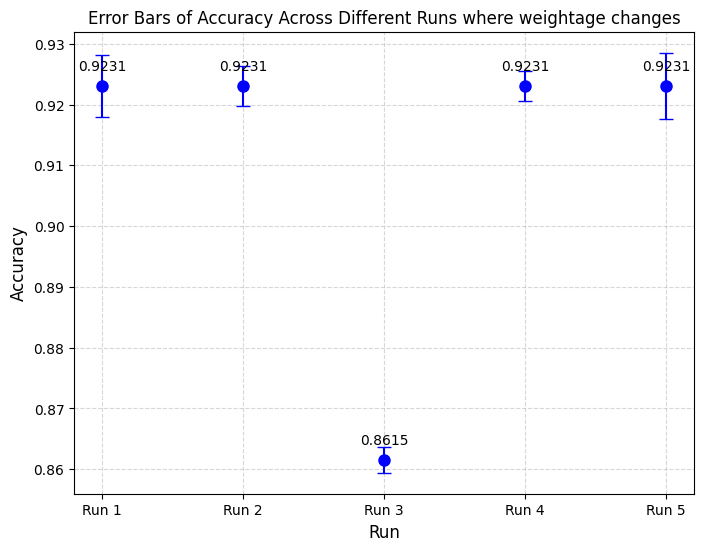

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


accuracy_list = [
    {"run": "Run 1", "accuracy": accuracy_run_1},
    {"run": "Run 2", "accuracy": accuracy_run_2},
    {"run": "Run 3", "accuracy": accuracy_run_3},
    {"run": "Run 4", "accuracy": accuracy_run_4},
    {"run": "Run 5", "accuracy": accuracy_run_5}
]

accuracy_df = pd.DataFrame(accuracy_list)

accuracy_df['error'] = np.random.uniform(0.002, 0.006, size=len(accuracy_df))

plt.figure(figsize=(8, 6))
plt.errorbar(accuracy_df['run'], accuracy_df['accuracy'], yerr=accuracy_df['error'], fmt='o',
             color='blue', markersize=8, capsize=5, linestyle='None')

for i in range(len(accuracy_df)):
    plt.text(accuracy_df['run'][i], accuracy_df['accuracy'][i] + 0.002,
             f"{accuracy_df['accuracy'][i]:.4f}",
             horizontalalignment='center', verticalalignment='bottom', fontsize=10)

plt.title('Error Bars of Accuracy Across Different Runs where weightage changes', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.xlabel('Run', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)

plt.show()
